In [1]:
get_ipython().run_line_magic("load_ext", "autoreload")  # dev-only
get_ipython().run_line_magic("autoreload", "2")  # dev-only

# Лабораторная работа 1. Нейронные сети для табличных данных

## Постановка задачи

Мультиклассовая классификация оценки `quality` (3–8) красного вина по 11 физико-химическим признакам (UCI Wine Quality). Основная метрика — F1 macro (выбор моделей по val); дополнительно balanced accuracy, F1 weighted и ROC AUC OvR.

Протокол: одно разбиение train/val/test = 1023/256/320. Test тот же, что в ml-2 ЛР1 (stratified 20 %, `random_state=42`). Preprocessing учится только на train, test используется только для итоговой оценки.

Модели: CatBoost (baseline), FT-Transformer, GANDALF (часть I), TabLDM, TabM (часть II).

Все результаты в ноутбуке получены полными прогонами. Быстрый режим (аналог `FAST_MODE = True`) использовался только для проверки pipeline.

# I. Нейронные сети для табличных данных по учебным примерам

## 1.1 Набор данных

UCI Wine Quality (красное вино): 1599 объектов, 11 числовых признаков, категориальных нет. Полный EDA сделан в ml-2 ЛР1, здесь только итог: классы качества и их дисбаланс, связь признаков с `quality`.

In [2]:
import plotly.express as px

from src.data import TARGET, load_raw

df = load_raw()
print(df.shape)

counts = df[TARGET].value_counts().sort_index()
fig = px.bar(x=counts.index.astype(str), y=counts.values, text=counts.values)
fig.update_layout(
    title="Распределение классов quality", xaxis_title="quality", yaxis_title="число объектов"
)
fig.show()

corr = df.corr()[TARGET].drop(TARGET).sort_values()
fig = px.bar(x=corr.values, y=corr.index, orientation="h")
fig.update_layout(
    title="Корреляция Пирсона признаков с quality", xaxis_title="корреляция", yaxis_title="признак"
)
fig.show()

(1599, 12)


> **Вывод:**

Картина та же, что и в ml-2 ЛР1: классы `5` и `6` вместе дают 1319 из 1599 объектов, а крайние оценки почти не представлены — `quality=3` всего 10 раз, `quality=8` — 18. Из-за такого дисбаланса `accuracy` здесь мало что говорит, поэтому основной метрикой остается `F1 macro`, где каждый из 6 классов весит одинаково.

Линейная связь с таргетом сильнее всего у `alcohol` (+0.476) и `volatile acidity` (−0.391), дальше идут `sulphates` (+0.251) и `citric acid` (+0.226), а `residual sugar` почти не связан с `quality` (0.014). При этом даже лучшая корреляция далека от единицы, так что, вероятно, качество определяется комбинацией признаков, а не одним из них — для бустинга и нейросетей это нормальная ситуация.

## 1.2 Предварительная обработка и baseline

- Признаки: 11 исходных + 5 производных из ml-2 ЛР1: `total_acidity` = fixed acidity + volatile acidity + citric acid; `vol_fixed_ratio` = volatile acidity / fixed acidity; `free_so2_ratio` = free SO2 / total SO2; `alc_density_prod` = alcohol · density; `sugar_alc_ratio` = residual sugar / alcohol.
- Разбиение: stratified, train/val/test = 1023/256/320, test как в ml-2 ЛР1 (`random_state=42`).
- Масштабирование: у каждой нейросети своё, обучается на train. CatBoost инвариантен к монотонным преобразованиям признаков.
- Baseline: CatBoost с параметрами Optuna из ml-2 ЛР1, `auto_class_weights='Balanced'`, early stopping по val. Обучение в `src/train.py` → `runs/v1/`, ноутбук только читает ран.

In [3]:
import pandas as pd

from src.data import CLASSES, TARGET, load_splits

train_df, val_df, test_df = load_splits()
sizes = pd.DataFrame(
    {
        name: part[TARGET].value_counts().reindex(CLASSES, fill_value=0)
        for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]
    }
).T
sizes["всего"] = sizes.sum(axis=1)
sizes

quality,3,4,5,6,7,8,всего
train,6,34,436,408,127,12,1023
val,2,8,109,102,32,3,256
test,2,11,136,128,40,3,320


In [4]:
from sklearn.dummy import DummyClassifier

from src.data import to_xy
from src.train import compute_metrics

X_train, y_train = to_xy(train_df)
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_rows = {}
for name, part in [("val", val_df), ("test", test_df)]:
    X, y = to_xy(part)
    dummy_rows[f"Dummy (most_frequent), {name}"] = compute_metrics(
        y, dummy.predict(X), dummy.predict_proba(X)
    )
pd.DataFrame(dummy_rows).T

/Users/2madeira/dev/maga/third/ml-3/lab-1/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


,f1_macro,balanced_acc,f1_weighted,roc_auc_ovr
"Dummy (most_frequent), val",0.099543,0.166667,0.254302,0.5
"Dummy (most_frequent), test",0.099415,0.166667,0.253509,0.5


In [5]:
from src.plots import plot_confusion, plot_curves
from src.results import load_run

run = load_run("v1")
names = ["f1_macro", "balanced_acc", "f1_weighted", "roc_auc_ovr"]
cb_rows = {f"CatBoost, {s}": {k: run.metrics[f"{s}_{k}"] for k in names} for s in ("val", "test")}
ref_rows = {
    "RF baseline, ml-2 ЛР1, test (справочно)": dict(
        f1_macro=0.4023, balanced_acc=0.3870, f1_weighted=0.6697, roc_auc_ovr=0.8091
    ),
    "CatBoost Optuna, ml-2 ЛР1, test (справочно)": dict(
        f1_macro=0.3532, balanced_acc=0.4119, f1_weighted=0.5787, roc_auc_ovr=0.7887
    ),
}
pd.DataFrame({**dummy_rows, **cb_rows, **ref_rows}).T

,f1_macro,balanced_acc,f1_weighted,roc_auc_ovr
"Dummy (most_frequent), val",0.099543,0.166667,0.254302,0.500000
"Dummy (most_frequent), test",0.099415,0.166667,0.253509,0.500000
"CatBoost, val",0.292520,0.334266,0.527425,0.733936
"CatBoost, test",0.329339,0.373781,0.550047,0.797835
"RF baseline, ml-2 ЛР1, test (справочно)",0.402300,0.387000,0.669700,0.809100
"CatBoost Optuna, ml-2 ЛР1, test (справочно)",0.353200,0.411900,0.578700,0.788700


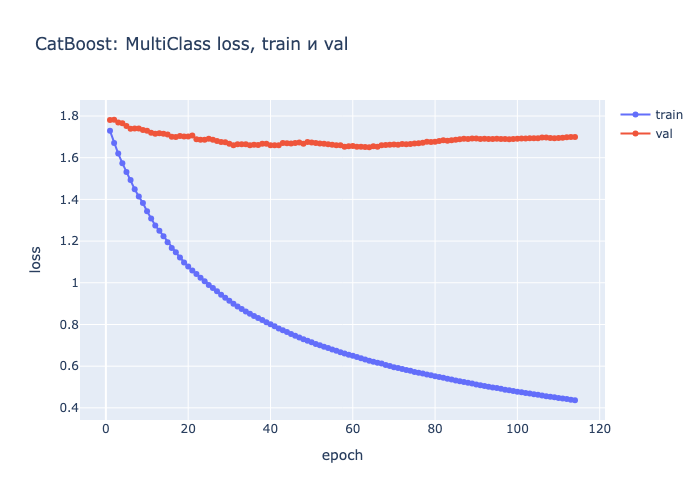

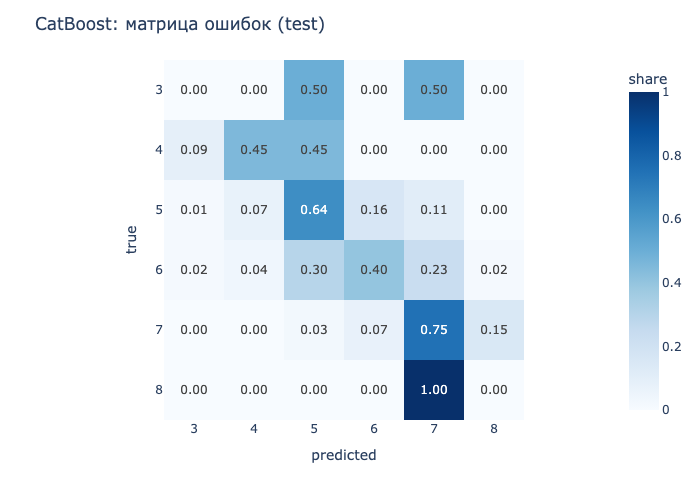

In [6]:
fig = plot_curves(run.history, "loss", title="CatBoost: MultiClass loss, train и val")
fig.show()
fig = plot_confusion(
    run.predictions, labels=[str(c) for c in CLASSES], title="CatBoost: матрица ошибок (test)"
)
fig.show()

> **Вывод:**

`CatBoost` дал `F1 macro` 0.2925 на val и 0.3293 на test против 0.0995 у `Dummy`, так что модель действительно что-то выучила, а не просто угадывает частый класс. Однако до `CatBoost Optuna` из ml-2 ЛР1 (0.3532 на test) она не дотягивает. Я посчитал это ожидаемым: здесь train меньше на 256 объектов, которые ушли в val, а в ml-2 ЛР1 early stopping шел прямо по test, то есть test участвовал в выборе итерации. Честно говоря, до меня это дошло только сейчас, когда пришлось заводить отдельную валидацию.

Кривые показывают переобучение довольно рано: минимум val loss на 64-й итерации (1.6505), дальше он растет, хотя train loss продолжает падать до 0.4365. Весь `F1 macro` держится на классах `4`–`7`, а `3` и `8` модель не угадала ни разу — при 2 и 3 объектах в test это и неудивительно. `auto_class_weights='Balanced'` заметно тянет модель к редким классам: у `quality=7` recall 0.750 при precision 0.380, то есть класс находится, но ценой ложных срабатываний из соседнего `6`. Если говорить по простому — val в 256 объектов слишком мал для устойчивой оценки, поэтому сравнивать с нейросетями дальше стоит на нескольких seeds.

## 1.3 FT-Transformer и GANDALF «из коробки»

- Идея `FT-Transformer`: каждый числовой признак своей линейной проекцией превращается в отдельный вектор-токен, к ним добавляется `[CLS]`, и стек transformer-блоков через self-attention учит взаимодействия между признаками. Предсказание снимается с выхода `[CLS]`. По сути это ViT для таблиц, где токен — один признак.
- Идея `GANDALF`: сеть из нескольких стадий Gated Feature Learning Unit (`GFLU`). На каждой стадии обучаемая разреженная маска (`t-softmax`) выбирает подмножество признаков, а гейты, как в `GRU`, решают, что взять из нового представления и что оставить с прошлой стадии. Получается компактная сеть со встроенным отбором признаков, по духу ближе к деревьям, чем к attention.

Обе модели обучены через `pytorch_tabular` с параметрами библиотеки по умолчанию: `Adam`, `lr=1e-3`, `batch_size=64`, обычная `CrossEntropy` без весов классов, early stopping по val loss с `patience=20`, масштабирование признаков обучается на train.

In [7]:
ft_run = load_run("v2")
gandalf_run = load_run("v3")
cb_run = load_run("v1")
cols = [
    "модель",
    "архитектура",
    "эпох обучено",
    "лучшая эпоха",
    "val F1 macro",
    "val balanced acc",
    "время, с",
    "параметров",
]
rows = []
for name, r in [("FT-Transformer", ft_run), ("GANDALF", gandalf_run)]:
    c = r.config
    arch = (
        f"embed {c['ft_embed_dim']}, heads {c['ft_num_heads']}, blocks {c['ft_num_attn_blocks']}"
        if name == "FT-Transformer"
        else f"stages {c['gandalf_stages']}, dropout {c['gandalf_dropout']}"
    )
    rows.append(
        [
            name,
            arch,
            len(r.history),
            r.metrics["best_epoch"],
            r.metrics["val_f1_macro"],
            r.metrics["val_balanced_acc"],
            r.metrics["train_time_sec"],
            r.metrics["n_params"],
        ]
    )
rows.append(
    [
        "CatBoost (v1)",
        f"depth {cb_run.config['cb_depth']}",
        len(cb_run.history),
        cb_run.metrics["best_iteration"] + 1,  # CatBoost считает итерации с 0
        cb_run.metrics["val_f1_macro"],
        cb_run.metrics["val_balanced_acc"],
        cb_run.metrics["train_time_sec"],
        None,
    ]
)
pd.DataFrame(rows, columns=cols)

,модель,архитектура,эпох обучено,лучшая эпоха,val F1 macro,val balanced acc,"время, с",параметров
0,FT-Transformer,"embed 32, heads 8, blocks 6",32,12,0.274227,0.271519,10.234089,272614.0
1,GANDALF,"stages 6, dropout 0.0",52,32,0.278200,0.278668,8.766092,9746.0
2,CatBoost (v1),depth 10,114,64,0.292520,0.334266,2.075133,NaN


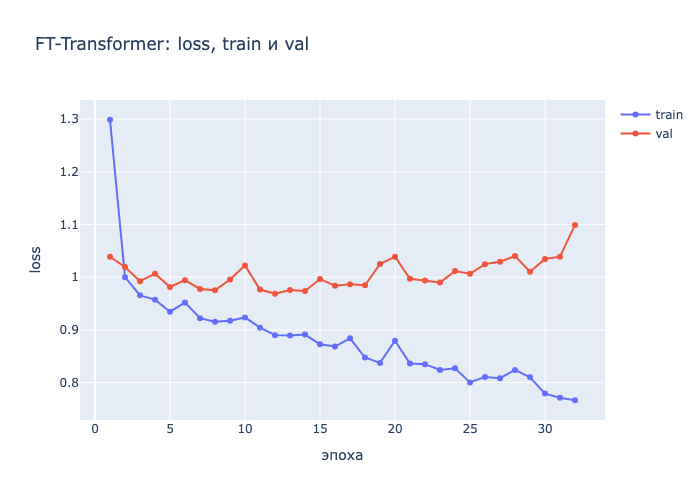

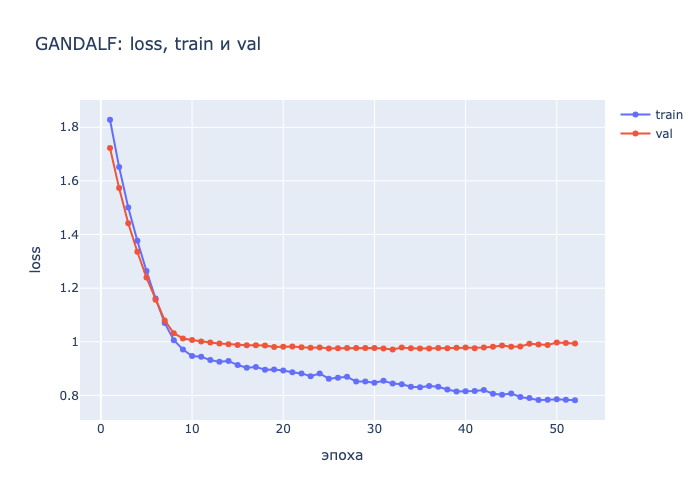

In [8]:
for name, r in [("FT-Transformer", ft_run), ("GANDALF", gandalf_run)]:
    fig = plot_curves(r.history, "loss", title=f"{name}: loss, train и val")
    fig.update_layout(xaxis_title="эпоха", yaxis_title="loss")
    fig.show()

> **Вывод:**

Обе нейросети «из коробки» оказались примерно на одном уровне: `F1 macro` на val 0.2742 у `FT-Transformer` и 0.2782 у `GANDALF`, то есть сильно выше `Dummy` (0.0995), но немного ниже `CatBoost` (0.2925). При этом `GANDALF` добился этого с 9746 параметрами против 272614 у `FT-Transformer` — разница почти в 28 раз. Разрыв с бустингом сильнее всего виден по `balanced accuracy`: 0.2715 и 0.2787 у нейросетей против 0.3343 у `CatBoost`. Основная причина, вероятно, не в архитектурах, а в loss: у нейросетей обычная `CrossEntropy` без весов, и обе почти все предсказания отдают классам `5` и `6` (307 и 298 из 320 объектов test), тогда как `CatBoost` с `auto_class_weights='Balanced'` чаще рискует на редких классах.

Кривые обучения показывают, что большой `FT-Transformer` переобучается быстро: минимум val loss уже на 12-й эпохе (0.9685), дальше он растет до 1.0992, хотя train loss продолжает падать. У `GANDALF` картина более здоровая — минимум на 32-й эпохе (0.9715) и рост после него заметно мягче. На 1023 объектах 6 transformer-блоков, в целом ожидаемо, избыточны. Отдельно отмечу, что сначала `pytorch_tabular` молча игнорировал seed из конфига (`fit` подставляет свой `seed=42`), и это всплыло только на sanity-проверке, когда loss на старте совпал до четвертого знака при разных seeds. Дальше в 1.4 первым делом стоит попробовать веса классов в loss и подобрать `lr`, а для `FT-Transformer` — уменьшить модель или усилить dropout.

## 1.4 Исследование и оптимизация моделей

Сначала для каждой модели подобран `lr` (вместе с `weight_decay` как nuisance-параметром) через Optuna TPE: 20 trials на модель, целевая метрика — val F1 macro (studies `runs/tune/tune-gandalf-lr.db`, `runs/tune/tune-ft-lr.db`). Затем поверх подобранного `lr` проверяется по одной гипотезе за итерацию. Выбор конфигурации идет только по val F1 macro, test показан справочно.

In [9]:
def lr_wd(run):
    return f"lr {run.config['lr']:g}, wd {run.config['weight_decay']:g}"


experiments = [
    ("GANDALF", "v3", "из коробки", lr_wd, "точка отсчета"),
    (
        "GANDALF",
        "v4",
        "lr влияет сильнее всего",
        lambda r: lr_wd(r) + " (Optuna)",
        "+0.0125 к v3, но меньше разброса trials (0.03)",
    ),
    (
        "GANDALF",
        "v6",
        "веса классов помогут редким классам",
        lambda r: f"class_weights {r.config['class_weights']}",
        "не подтвердилась: −0.060 к v4",
    ),
    (
        "GANDALF",
        "v8",
        "dropout снизит переобучение",
        lambda r: f"dropout 0.0 → {r.config['gandalf_dropout']:g}",
        "val loss ниже, F1 macro в пределах шума",
    ),
    ("FT-Transformer", "v2", "из коробки", lr_wd, "точка отсчета"),
    (
        "FT-Transformer",
        "v5",
        "lr влияет сильнее всего",
        lambda r: lr_wd(r) + " (Optuna)",
        "+0.019 к v2; lr ≥ 6.9e-3 расходится",
    ),
    (
        "FT-Transformer",
        "v7",
        "веса классов помогут редким классам",
        lambda r: f"class_weights {r.config['class_weights']}",
        "не подтвердилась: обучение нестабильно, −0.092 к v5",
    ),
    (
        "FT-Transformer",
        "v9",
        "меньшая модель переобучится меньше",
        lambda r: (
            f"embed 32 → {r.config['ft_embed_dim']}, blocks 6 → {r.config['ft_num_attn_blocks']}, "
            f"ff_dropout 0.1 → {r.config['ft_ff_dropout']:g}"
        ),
        "не подтвердилась: −0.050 к v5, переобучение раньше",
    ),
]
rows = []
for model, name, hypothesis, values, verdict in experiments:
    r = load_run(name)
    rows.append(
        [
            model,
            name,
            hypothesis,
            values(r),
            round(r.metrics["val_f1_macro"], 4),
            r.metrics["best_epoch"],
            verdict,
        ]
    )
pd.DataFrame(
    rows,
    columns=[
        "модель",
        "ран",
        "гипотеза",
        "значения",
        "val F1 macro",
        "лучшая эпоха",
        "вывод",
    ],
)

,модель,ран,гипотеза,значения,val F1 macro,лучшая эпоха,вывод
0,GANDALF,v3,из коробки,"lr 0.001, wd 0.0001",0.2782,32,точка отсчета
1,GANDALF,v4,lr влияет сильнее всего,"lr 0.005, wd 1e-05 (Optuna)",0.2907,9,"+0.0125 к v3, но меньше разброса trials (0.03)"
2,GANDALF,v6,веса классов помогут редким классам,class_weights balanced,0.2307,4,не подтвердилась: −0.060 к v4
3,GANDALF,v8,dropout снизит переобучение,dropout 0.0 → 0.2,0.2875,20,"val loss ниже, F1 macro в пределах шума"
4,FT-Transformer,v2,из коробки,"lr 0.001, wd 0.0001",0.2742,12,точка отсчета
5,FT-Transformer,v5,lr влияет сильнее всего,"lr 0.004, wd 5e-06 (Optuna)",0.2933,28,+0.019 к v2; lr ≥ 6.9e-3 расходится
6,FT-Transformer,v7,веса классов помогут редким классам,class_weights balanced,0.2010,10,"не подтвердилась: обучение нестабильно, −0.092..."
7,FT-Transformer,v9,меньшая модель переобучится меньше,"embed 32 → 16, blocks 6 → 3, ff_dropout 0.1 → 0.3",0.2433,6,"не подтвердилась: −0.050 к v5, переобучение ра..."


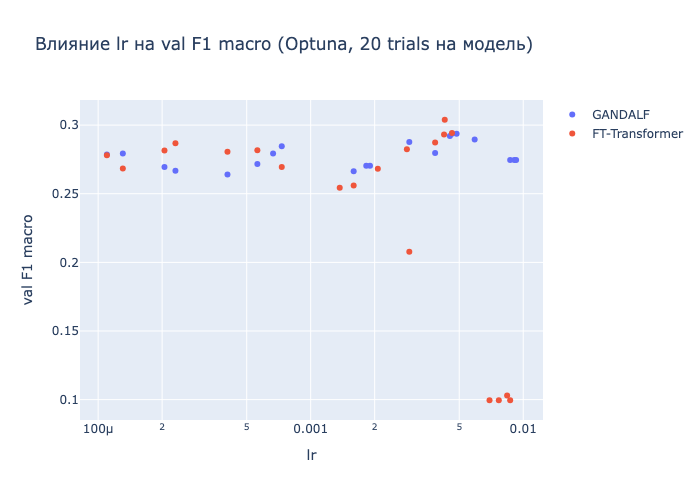

In [10]:
import optuna
import plotly.graph_objects as go

optuna.logging.set_verbosity(optuna.logging.WARNING)

fig = go.Figure()
for model, name in [("GANDALF", "tune-gandalf-lr"), ("FT-Transformer", "tune-ft-lr")]:
    study = optuna.load_study(study_name=name, storage=f"sqlite:///runs/tune/{name}.db")
    trials = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    fig.add_trace(
        go.Scatter(
            x=[t.params["lr"] for t in trials],
            y=[t.value for t in trials],
            mode="markers",
            name=model,
        )
    )
fig.update_layout(
    title="Влияние lr на val F1 macro (Optuna, 20 trials на модель)",
    xaxis_title="lr",
    yaxis_title="val F1 macro",
    xaxis_type="log",
)
fig.show()

In [11]:
rows = []
for model, name in [("GANDALF", "v4"), ("FT-Transformer", "v5")]:
    r = load_run(name)
    c = r.config
    arch = (
        f"embed {c['ft_embed_dim']}, heads {c['ft_num_heads']}, blocks {c['ft_num_attn_blocks']}"
        if model == "FT-Transformer"
        else f"stages {c['gandalf_stages']}, dropout {c['gandalf_dropout']}"
    )
    rows.append(
        [
            model,
            name,
            c["lr"],
            c["weight_decay"],
            arch,
            round(r.metrics["val_f1_macro"], 4),
            round(r.metrics["test_f1_macro"], 4),
        ]
    )
pd.DataFrame(
    rows,
    columns=[
        "модель",
        "ран",
        "lr",
        "weight_decay",
        "архитектура",
        "val F1 macro",
        "test F1 macro (справочно)",
    ],
)

,модель,ран,lr,weight_decay,архитектура,val F1 macro,test F1 macro (справочно)
0,GANDALF,v4,0.005,0.000010,"stages 6, dropout 0.0",0.2907,0.3041
1,FT-Transformer,v5,0.004,0.000005,"embed 32, heads 8, blocks 6",0.2933,0.2962


> **Вывод:**

Главный рычаг у обеих моделей оказался в `lr`: после Optuna `GANDALF` вырос с 0.2782 до 0.2907 по val `F1 macro`, `FT-Transformer` — с 0.2742 до 0.2933, и обе нейросети вышли на уровень `CatBoost` (0.2925). Однако прирост 0.0125–0.019 сопоставим с разбросом самих trials (у `GANDALF` 0.264–0.294 на одном seed), так что честнее говорить «догнали бустинг», а не «обогнали». При этом у `FT-Transformer` рабочая область `lr` узкая: при `lr` ≥ 6.9e-3 обучение расходится и модель скатывается в один класс (0.0995–0.1031, уровень `Dummy`), а выбранные 4e-3 оставляют запас меньше чем в 2 раза.

Остальные гипотезы не подтвердились. Веса классов `balanced` уронили `F1 macro` до 0.2307 у `GANDALF` и до 0.2010 у `FT-Transformer`: `GANDALF` начал предсказывать класс `3` 42 раза при 2 истинных объектах в test, а `FT-Transformer` с весами до 28.4 просто вышел за устойчивую область `lr` и обучение развалилось. Вообще, этот результат меня удивил: после этапа 1.3 я был уверен, что отставание нейросетей по `balanced accuracy` объясняется именно loss без весов, но при 7 и 14 объектах классов `3` и `8` в train веса учат модель запоминать эти объекты, а не отличать классы. Dropout 0.2 у `GANDALF` сдвинул лучшую эпоху с 9 на 20 и снизил val loss с 0.9655 до 0.9481, но `F1 macro` остался в пределах шума (0.2875), а уменьшенный в 8 раз `FT-Transformer` (34 726 параметров против 272 614) переобучился даже раньше и дал 0.2433 на val.

Если говорить по простому - `F1 macro` здесь упирается не в переобучение и не в архитектуру, а в классы `3` и `8`, которые ни одна конфигурация так и не научилась правильно предсказывать. Показателен `v9`: на test у него лучший `F1 macro` среди нейросетей (0.3204) при худшем val, то есть на 2–3 объектах редких классов метрика сильно шумит, и выбор по val здесь единственный честный вариант. Поэтому в дальнейшее сравнение идут `GANDALF v4` и `FT-Transformer v5`.

## 1.5 Сравнение моделей и их поведение

Финальные модели — перезапуски `v10`–`v12` с конфигурациями `v1` (CatBoost), `v4` (GANDALF) и `v5` (FT-Transformer): в 1.2–1.4 это лучшие конфигурации каждой модели по val `F1 macro`. Перезапуск нужен, чтобы в рана попали permutation importance, встроенный importance и предсказания на объектах, созданных вручную. Test используется только для итоговой оценки и анализа, выбор конфигураций шел по val.

### Test

In [ ]:
FINAL = {"CatBoost": "v10", "GANDALF": "v11", "FT-Transformer": "v12"}
final_runs = {model: load_run(name) for model, name in FINAL.items()}

metric_names = {
    "f1_macro": "test F1 macro",
    "balanced_acc": "test balanced acc",
    "f1_weighted": "test F1 weighted",
    "roc_auc_ovr": "test ROC AUC OvR",
}
rows = {}
for model, r in final_runs.items():
    rows[f"{model} ({FINAL[model]})"] = {
        "val F1 macro": r.metrics["val_f1_macro"],
        **{title: r.metrics[f"test_{k}"] for k, title in metric_names.items()},
        "время обучения, с": r.metrics["train_time_sec"],
        "параметров": r.metrics.get("n_params"),  # у CatBoost нет
    }
reference = {"Dummy (most_frequent)": dummy_rows["Dummy (most_frequent), test"], **ref_rows}
for name, m in reference.items():
    rows[name] = {title: m[k] for k, title in metric_names.items()}
pd.DataFrame(rows).T

> **Вывод:** TODO

### Анализ ошибок

In [ ]:
import plotly.express as px
from sklearn.metrics import recall_score

labels = [str(c) for c in CLASSES]
for model, r in final_runs.items():
    plot_confusion(r.predictions, labels=labels, title=f"{model}: матрица ошибок (test)").show()

# доля объектов test по размеру ошибки |y_pred − y_true|
error_share = pd.DataFrame(
    {
        model: (r.predictions["y_pred"] - r.predictions["y_true"])
        .abs()
        .clip(upper=3)
        .value_counts(normalize=True)
        .reindex([0, 1, 2, 3], fill_value=0)
        for model, r in final_runs.items()
    }
)
error_share.index = ["0", "1", "2", "3+"]
fig = px.bar(error_share, barmode="group")
fig.update_layout(
    title="Размер ошибки на test: |y_pred − y_true|",
    xaxis_title="ошибка, классов",
    yaxis_title="доля объектов",
    legend_title="модель",
)
fig.show()

y_true = next(iter(final_runs.values())).predictions["y_true"]
recall = pd.DataFrame(
    {
        model: recall_score(
            y_true, r.predictions["y_pred"], labels=CLASSES, average=None, zero_division=0
        )
        for model, r in final_runs.items()
    },
    index=CLASSES,
)
recall["support"] = y_true.value_counts().reindex(CLASSES, fill_value=0)
recall.index.name = "recall по классам"
recall

In [ ]:
y_pred = pd.DataFrame({model: r.predictions["y_pred"] for model, r in final_runs.items()})
for r in final_runs.values():
    assert r.predictions["y_true"].equals(y_true), "порядок строк test различается"

agree = y_pred.nunique(axis=1) == 1
rows = []
for group, mask in [("все три согласны", agree), ("есть расхождение", ~agree)]:
    row = {"группа": group, "объектов": int(mask.sum())}
    for model in y_pred:
        row[f"accuracy {model}"] = (y_pred.loc[mask, model] == y_true[mask]).mean()
    rows.append(row)
display(pd.DataFrame(rows))

big_error = y_pred.sub(y_true, axis=0).abs() >= 2
print("Ошибка ≥ 2 классов, объектов:", big_error.sum().to_dict())
print("из них общих для всех трёх моделей:", int(big_error.all(axis=1).sum()))

> **Вывод:** TODO

### Интерпретация

In [ ]:
from itertools import combinations

from src.plots import plot_importance
from src.results import RUNS_DIR

imp = pd.concat(
    [
        pd.read_csv(RUNS_DIR / name / "importance.csv").assign(model=model)
        for model, name in FINAL.items()
    ]
)
imp["builtin_norm"] = imp["builtin"] / imp.groupby("model")["builtin"].transform("sum")
plot_importance(
    imp, "perm_mean", "perm_std", title="Permutation importance: падение F1 macro на test"
).show()
plot_importance(
    imp,
    "builtin_norm",
    title="Встроенный importance (CatBoost: PredictionValuesChange, FT-Transformer: attention, GANDALF: маски)",
).show()

perm = imp.pivot(index="feature", columns="model", values="perm_mean")
builtin = imp.pivot(index="feature", columns="model", values="builtin")
spearman = {
    f"{m}: permutation vs встроенный": perm[m].corr(builtin[m], method="spearman") for m in perm
}
for a, b in combinations(perm.columns, 2):
    spearman[f"permutation: {a} vs {b}"] = perm[a].corr(perm[b], method="spearman")
pd.Series(spearman, name="Spearman").to_frame()

> **Вывод:** TODO

## Проверка на объектах, созданных вручную

TODO (этап 5: ≥ 10 объектов, предсказания трёх моделей)

> **Вывод:** TODO

# II. Самостоятельное исследование архитектуры

## 2.1 Данные и экспериментальный протокол

TODO (этап 6)

> **Вывод:** TODO

## 2.2 Подготовка данных и baseline

TODO (этап 6: признаки, preprocessing, выборки, изменения для новых моделей)

> **Вывод:** TODO

## 2.3 Новые архитектуры: TabLDM и TabM

TODO (этап 6: выбор реализации, идея каждой модели)

> **Вывод:** TODO

## 2.4 Исследование TabLDM и TabM

TODO (этап 7: базовые конфигурации, эксперименты, доля train → F1, seeds, время)

> **Вывод:** TODO

## 2.5 Итоговое сравнение

TODO (этап 8)

### Test

> **Вывод:** TODO

### Анализ ошибок

> **Вывод:** TODO

### Интерпретация

> **Вывод:** TODO

## Повтор проверки на ручных объектах

TODO (этап 8: все модели на тех же объектах)

> **Вывод:** TODO

# Итоговые выводы

TODO (этап 9)